In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re

df = pd.read_csv("fakenews.csv")

df["headline"] = df["headline"].fillna("")
df["body_text"] = df["body_text"].fillna("")
df["text"] = df["headline"] + " " + df["body_text"]

In [2]:
from nrclex import NRCLex
import re
from collections import Counter

emotions = [
    "anger", "anticipation", "disgust", "fear",
    "joy", "sadness", "surprise", "trust"
]

nrc_lexicon = NRCLex("happy").__dict__["__lexicon__"]

def get_emotions(text):
    words = re.findall(r"\b[a-z]+\b", str(text).lower())
    counts = Counter()

    for word in words:
        if word in nrc_lexicon:
            for emotion in nrc_lexicon[word]:
                if emotion in emotions:
                    counts[emotion] += 1

    return {emotion: counts[emotion] for emotion in emotions}

emotion_scores = df["text"].apply(get_emotions)
emotion_df = pd.DataFrame(emotion_scores.tolist())

df = pd.concat([df, emotion_df], axis=1)

print(df[["label"] + emotions].head())

  label  anger  anticipation  disgust  fear  joy  sadness  surprise  trust
0  Real      1             1        1     1    2        1         1      2
1  Real      1             1        0     3    0        1         1      1
2  Fake      0             0        0     0    0        0         0      0
3  Fake      0             1        0     0    2        0         1      1
4  Real      1             1        0     2    0        0         0      1


In [3]:
from nrclex import NRCLex

test = NRCLex("I am happy but also afraid")
print(test.__dict__)

{'__lexicon__': {'abacus': ['trust'], 'abandon': ['fear', 'negative', 'sadness'], 'abandoned': ['anger', 'fear', 'negative', 'sadness'], 'abandonment': ['anger', 'fear', 'negative', 'sadness', 'surprise'], 'abba': ['positive'], 'abbot': ['trust'], 'abduction': ['fear', 'negative', 'sadness', 'surprise'], 'aberrant': ['negative'], 'aberration': ['disgust', 'negative'], 'abhor': ['anger', 'disgust', 'fear', 'negative'], 'abhorrent': ['anger', 'disgust', 'fear', 'negative'], 'ability': ['positive'], 'abject': ['disgust', 'negative'], 'abnormal': ['disgust', 'negative'], 'abolish': ['anger', 'negative'], 'abolition': ['negative'], 'abominable': ['disgust', 'fear', 'negative'], 'abomination': ['anger', 'disgust', 'fear', 'negative'], 'abort': ['negative'], 'abortion': ['disgust', 'fear', 'negative', 'sadness'], 'abortive': ['negative', 'sadness'], 'abovementioned': ['positive'], 'abrasion': ['negative'], 'abrogate': ['negative'], 'abrupt': ['surprise'], 'abscess': ['negative', 'sadness'], '

In [4]:
emotion_comparison = df.groupby("label")[emotions].mean().round(3)

print(emotion_comparison)

       anger  anticipation  disgust   fear    joy  sadness  surprise  trust
label                                                                      
Fake   0.391         0.294    0.213  1.004  0.195    0.302     0.314  0.629
Real   0.411         0.284    0.192  0.974  0.203    0.310     0.302  0.566


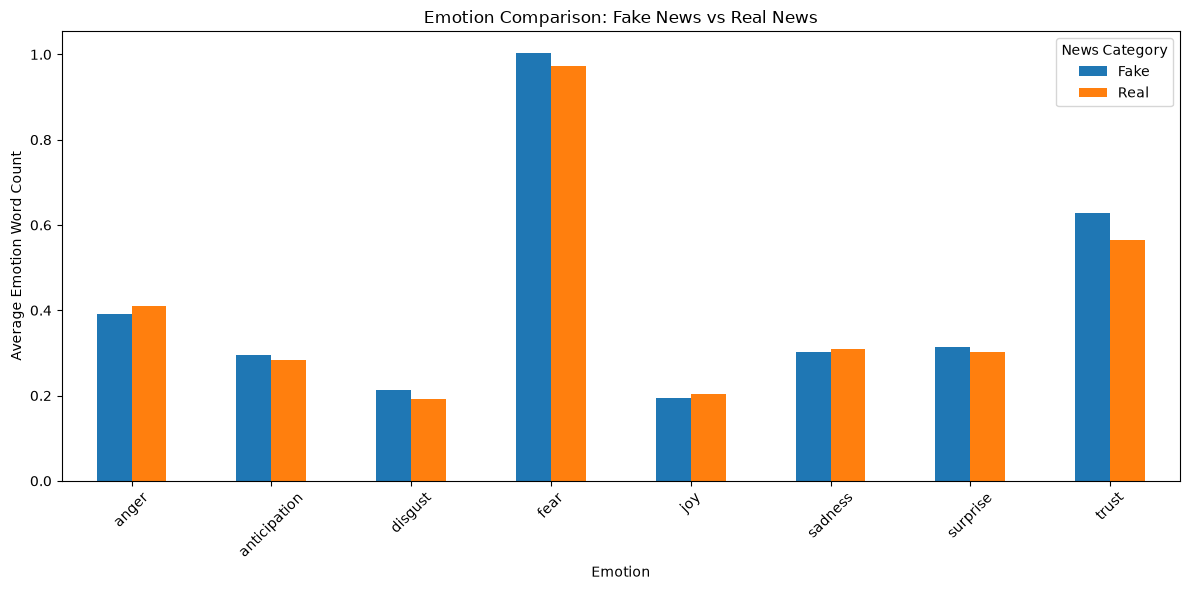

In [5]:
emotion_comparison.T.plot(kind="bar", figsize=(12, 6))

plt.title("Emotion Comparison: Fake News vs Real News")
plt.xlabel("Emotion")
plt.ylabel("Average Emotion Word Count")
plt.xticks(rotation=45)
plt.legend(title="News Category")
plt.tight_layout()
plt.show()

In [6]:
emotion_totals = df.groupby("label")[emotions].sum()

emotion_percentages = emotion_totals.div(
    emotion_totals.sum(axis=1).replace(0, 1), axis=0
) * 100

print(emotion_percentages.round(2))

       anger  anticipation  disgust   fear   joy  sadness  surprise  trust
label                                                                     
Fake   11.71          8.79     6.37  30.05  5.83     9.04      9.39  18.83
Real   12.67          8.76     5.93  30.02  6.27     9.57      9.32  17.46


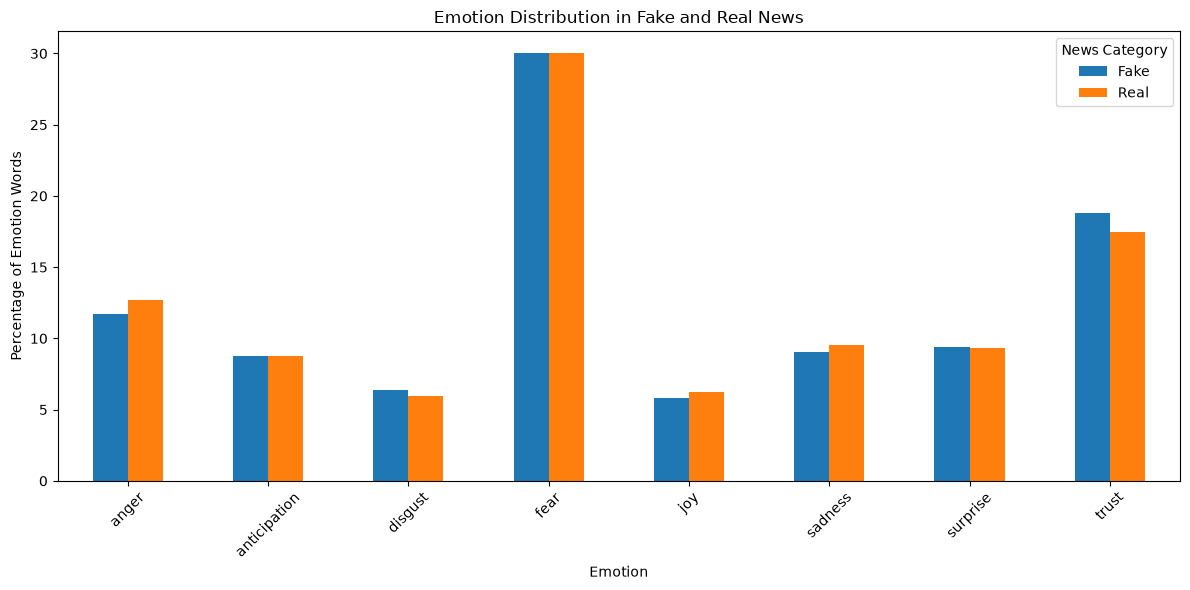

In [7]:
emotion_percentages.T.plot(kind="bar", figsize=(12, 6))

plt.title("Emotion Distribution in Fake and Real News")
plt.xlabel("Emotion")
plt.ylabel("Percentage of Emotion Words")
plt.xticks(rotation=45)
plt.legend(title="News Category")
plt.tight_layout()
plt.show()

In [8]:
df.to_csv("T32_nrc_emotion_analysis.csv", index=False)
emotion_comparison.to_csv("T32_emotion_comparison.csv")
emotion_percentages.to_csv("T32_emotion_percentages.csv")

print("Emotion analysis completed successfully!")

Emotion analysis completed successfully!
